# Experiment 2.3 · LeNet-5 Backpropagation and first tests

In Experiment 2.2, I built the forward pass, and now backward/step (backpropagation) is implemented on all layers

In [1]:
import sys
from pathlib import Path

import numpy as np

# the repository root in my computer
REPO_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "pyproject.toml").exists())
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

# numpy setting
np.set_printoptions(precision=4, suppress=True)

## T1 - The hand trace in code

**Call your convolution, ReLU and pooling procedures, forward and then backward, on the Part A example (a few lines in a main). Compare dA, dZ, dK and db with your hand computation. If they differ, find out which one is wrong.**

### From part A - by hand


**Given:**  
* z = [2, 1, 0]
* class label = 0 --> [1, 0, 0]
* dp is matrix below:
$$
\begin{bmatrix}
1 & -1 \\
2 & 1
\end{bmatrix}
$$

**A1:**  
* [1] 4-decimal approximations:  
Softmax(z) = [0.6652, 0.2447, 0.090]  
Loss = -ln(0.6642) = 0.4077


* [2] dz = [0.6522 - 1, 0.2477, 0.090] = [-0.3348, 0.2447, 0.090]

**A2:**  
* [1] dA is matrix below:
$$
\begin{bmatrix}
0 & 0 & -1 & 0 \\
0 & 1 & 0 & 0 \\
0 & 0 & 1 & 0 \\
2 & 0 & 0 & 0 
\end{bmatrix}
$$

* [2] dz is matrix below:
$$
\begin{bmatrix}
0 & 0 & -1 & 0 \\
0 & 1 & 0 & 0 \\
0 & 0 & 0 & 0 \\
2 & 0 & 0 & 0 
\end{bmatrix}
$$

* [3] dK and db is calculated below:  
db = -1 + 1 + 2 = 2  
dK is matrix below:
$$
\begin{bmatrix}
0 & 0 & -1 & 0 \\
0 & 1 & 0 & 0 \\
0 & 0 & 1 & 0 \\
2 & 0 & 0 & 0 
\end{bmatrix}
$$

* [4] $K_{new}$ and $b_{new}$ is calculated below:  
$b_{new}$ = -2 - 0.1(2) = -2.2  
$K_{new}$ is matrix below:
$$
\begin{bmatrix}
0.8 & -0.4 & -1 \\
1.3 & 0.3 & -0.1 \\
-0.1 & -0.4 & 1  
\end{bmatrix}
$$

**A2:**  
* [1] dA is matrix below:
$$
\begin{bmatrix}
0 & 0 & -1 & 0 \\
0 & 1 & 0 & 0 \\
0 & 0 & 1 & 0 \\
2 & 0 & 0 & 0 
\end{bmatrix}
$$

* [2] dz is matrix below:
$$
\begin{bmatrix}
0 & 0 & -1 & 0 \\
0 & 1 & 0 & 0 \\
0 & 0 & 0 & 0 \\
2 & 0 & 0 & 0 
\end{bmatrix}
$$

* [3] dK and db is calculated below:  
db = -1 + 1 + 2 = 2  
dK is matrix below:
$$
\begin{bmatrix}
0 & 0 & -1 & 0 \\
0 & 1 & 0 & 0 \\
0 & 0 & 1 & 0 \\
2 & 0 & 0 & 0 
\end{bmatrix}
$$

* [4] $K_{new}$ and $b_{new}$ is calculated below:  
$b_{new}$ = -2 - 0.1(2) = -2.2  
$K_{new}$ is matrix below:
$$
\begin{bmatrix}
0.8 & -0.4 & -1 \\
1.3 & 0.3 & -0.1 \\
-0.1 & -0.4 & 1  
\end{bmatrix}
$$

### Imports For Hand Check

In [2]:
from cnn import Conv2D, MaxPool2D
from numpy_utils import ACTIVATIONS, COSTS
from numpy_utils.activations import relu_derivative, softmax_derivative

### A1 - Softmax and cross-entropy

The output layer is a `numpy_nn.Layer` with softmax: the cost derivative `dC/dp` goes through the softmax derivative to give `dz`. For cross-entropy that chain collapses to `p - onehot(label)`.

In [3]:
z = np.array([[2.0, 1.0, 0.0]])
label = 0
target = np.eye(3)[[label]]

p = ACTIVATIONS.SOFTMAX.function(z)
loss = COSTS.CROSS_ENTROPY.function(p, target)
dz = ACTIVATIONS.SOFTMAX.derivative(p, COSTS.CROSS_ENTROPY.derivative(p, target)) # type: ignore

print(f"p: {p[0, 0]:.4f}, {p[0, 1]:.4f}, {p[0, 2]:.4f}")
print(f"loss: {loss:.4f}")
print(f"dz: {dz[0, 0]:.4f}, {dz[0, 1]:.4f}, {dz[0, 2]:.4f}")

p: 0.6652, 0.2447, 0.0900
loss: 0.4076
dz: -0.3348, 0.2447, 0.0900


### A2 · Convolution, ReLU and pooling, backwards

**Lab 1 Example and Learning Rate**

In [4]:
LEARNING_RATE = 0.1

X = np.array([
    [2.0, 0.0, 1.0, 0.0, 1.0, 0.0],
    [3.0, 1.0, 2.0, 1.0, 2.0, 3.0],
    [1.0, 3.0, 2.0, 1.0, 2.0, 3.0],
    [1.0, 1.0, 0.0, 0.0, 1.0, 3.0],
    [3.0, 3.0, 1.0, 0.0, 1.0, 1.0],
    [1.0, 0.0, 1.0, 2.0, 2.0, 3.0]
])

K = np.array([
    [1.0, 0.0, -1.0],
    [2.0, 1.0, 0.0],
    [0.0, -1.0, 1.0]
])

B = -2.0

dP = np.array([
    [1.0, -1.0],
    [2.0,  1.0]
])

**Forward** - Uses `Conv2D` --> `Z` (`last_z`) --> ReLU output `A`

In [5]:
# Lab 1, Part 1B

# weights take (out_ch, in_ch, k_r, k_c) shape
# K has shape of (k_r, k_c) so new axis for in_ch and out_ch is added
conv_weights = K.copy()[np.newaxis, np.newaxis, :, :]
conv_bias = np.full((1, 1, 1), B)

conv = Conv2D(weights=conv_weights, bias=conv_bias, activation=ACTIVATIONS.RELU)
pool = MaxPool2D(pool_rows=2, pool_cols=2, stride=2)

# X has shape of (in_ch, in_r, in_c) so new axis for batch and in_ch is added
X_converted = X[np.newaxis, np.newaxis, :, :]

A = conv.forward(X_converted)
Z = conv.last_z
P = pool.forward(A)

print(f"A: {A[0, 0]}\n")
print(f"Z: {Z[0, 0]}\n")
print(f"P: {P[0, 0]}")

A: [[5. 1. 4. 3.]
 [3. 6. 4. 2.]
 [0. 1. 0. 0.]
 [9. 7. 0. 0.]]

Z: [[ 5.  1.  4.  3.]
 [ 3.  6.  4.  2.]
 [-2.  1. -1. -3.]
 [ 9.  7. -1. -3.]]

P: [[6. 4.]
 [9. 0.]]


**Backward** - `pool.backward(dP)` sends each gradient to its window's winner, which gives `dA`. Inside `conv.backward(dA)` the ReLU derivative turns `dA` into `dZ` (zero wherever `Z <= 0`), and from `dZ` it builds the kernel and bias gradients. `Conv2D` does not keep `dZ`, so it is recomputed below with the same ReLU derivative the layer uses. `argmax` returns the first maximum in row-major order, which is the handout's "first maximum, row by row".

In [6]:
# delta has shape of (batch, out_ch, out_r, out_c) so new axis for batch and out_ch is added
dP_converted = dP[np.newaxis, np.newaxis, :, :]

dA = pool.backward(dP_converted)
dZ = ACTIVATIONS.RELU.derivative(A, dA) # type: ignore
conv.backward(dA)
dK = conv.weight_gradient
db = conv.bias_gradient

conv.step(LEARNING_RATE)
new_K = conv.weights
new_b = conv.bias

print("A2 Part 1")
print(f"dA: {dA[0, 0]}\n")

print("A2 Part 2")
print(f"dZ: {dZ[0, 0]}\n")

print("A2 Part 3")
print(f"dK: {dK[0, 0]}\n")
print(f"db: {db[0, 0]}\n")

print("A2 Part 4")
print(f"new_K: {new_K[0, 0]}\n")
print(f"new_b: {new_b[0, 0]}")

A2 Part 1
dA: [[ 0.  0. -1.  0.]
 [ 0.  1.  0.  0.]
 [ 0.  0.  1.  0.]
 [ 2.  0.  0.  0.]]

A2 Part 2
dZ: [[ 0.  0. -1.  0.]
 [ 0.  1.  0.  0.]
 [ 0.  0.  0.  0.]
 [ 2.  0.  0.  0.]]

A2 Part 3
dK: [[ 2.  4.  0.]
 [ 7.  7.  1.]
 [ 1. -1.  0.]]

db: [2.]

A2 Part 4
new_K: [[ 0.8 -0.4 -1. ]
 [ 1.3  0.3 -0.1]
 [-0.1 -0.9  1. ]]

new_b: [-2.2]


**The code matches the hand computed backward from Part A**

## T2 - One step downhill

**Take the first MNIST training image. Print the loss, call train once on that image, and print the loss on the same image again. The loss must go down. If it goes up, a sign is wrong somewhere.**

In [7]:
from lenet5 import LeNet5
from lenet5.model_config import OUTPUT_UNITS
from mnist import read_images, read_labels

DATA_DIR = REPO_ROOT / "data" / "mnist"
SEED = 42
STEP_LEARNING_RATE = 0.01

train_images = read_images(DATA_DIR / "train-images-idx3-ubyte")
train_labels = read_labels(DATA_DIR / "train-labels-idx1-ubyte")

# first training image as a batch of one: (28, 28) -> (1, 1, 28, 28), pixels scaled to 0-1
image = train_images[0][np.newaxis, np.newaxis, :, :] / 255.0
label = int(train_labels[0])
target = np.eye(OUTPUT_UNITS)[[label]]

print(f"image: {image.shape}, label: {label}")

image: (1, 1, 28, 28), label: 5


**train** - `LeNet5` has `forward`, `backward` and `step`, so one training step on one image is: forward, cross-entropy loss, backward with `dC/dp`, then `step`.

In [8]:
def compute_gradients(net, inputs, targets):
    predicted = net.forward(inputs)
    net.backward(COSTS.CROSS_ENTROPY.derivative(predicted, targets))
    return COSTS.CROSS_ENTROPY.function(predicted, targets)

def train(net, inputs, targets, learning_rate):
    loss = compute_gradients(net, inputs, targets)
    net.step(learning_rate)
    return loss

def loss_of(net, inputs, targets):
    return COSTS.CROSS_ENTROPY.function(net.forward(inputs), targets)

In [9]:
net = LeNet5(seed=SEED)

loss_before = loss_of(net, image, target)
train(net, image, target, STEP_LEARNING_RATE)
loss_after = loss_of(net, image, target)

print(f"loss before: {loss_before:.6f}")
print(f"loss after:  {loss_after:.6f}")
print(f"loss went down: {loss_after < loss_before}")

loss before: 2.288568
loss after:  2.275991
loss went down: True


## T3 - Finite-difference gradient check

**Write a small method that checks the gradient of one parameter w on one training image:**

h = 0.00001  
// the gradient your backward pass computes  
run forward and backward on (image, label) WITHOUT updating the weights  
analytic = the gradient your code stored for w  
// the gradient measured by nudging w  
original = w  
w = original + h; lossPlus = loss after a forward pass on (image, label)  
w = original - h; lossMinus = loss after a forward pass on (image, label)  
w = original  
numeric = (lossPlus - lossMinus) / (2 * h)  
relativeError = |analytic - numeric| / max(|analytic|, |numeric|)  

**For "without updating", a method that does everything train does except the final update works well. Check one weight and one bias in each of C1, C3, C5, F6 and the output layer (10 parameters) and report them in a table. Choose parameters whose gradient is not zero. A correct implementation gives relative errors well below 0.00001.**

In [10]:
H = 0.00001

# the attribute backward stores each parameter's gradient in, for Conv2D and Layer alike
GRADIENT_NAMES = {"weights": "weight_gradient", "bias": "bias_gradient"}


def gradient_check(net, inputs, targets, layer, parameter, index):
    # the gradient the backward pass computes, without updating the weights
    compute_gradients(net, inputs, targets)
    analytic = getattr(layer, GRADIENT_NAMES[parameter])[index]

    # the gradient measured by nudging w (the layer's own array, changed in place)
    w = getattr(layer, parameter)
    original = w[index]
    w[index] = original + H
    loss_plus = loss_of(net, inputs, targets)
    w[index] = original - H
    loss_minus = loss_of(net, inputs, targets)
    w[index] = original

    numeric = (loss_plus - loss_minus) / (2 * H)
    relative_error = abs(analytic - numeric) / max(abs(analytic), abs(numeric))
    return analytic, numeric, relative_error

**ReLU's kink at 0** - nothing is wrong, but nudging the bias by ±h puts those `z` at +h and -h, so the finite difference measures the average slope, 1/2. A bias moves every `z` of its map, so it hits these pixels; a weight only moves `z` where its pixel is not 0, so it does not.

In [11]:
fresh = LeNet5(seed=SEED)
compute_gradients(fresh, image, target)

c1_z = fresh.c1_layer.last_z
print(f"C1 pre-activations exactly 0: {np.sum(c1_z == 0)} of {c1_z.size}")

index = tuple(int(i) for i in np.unravel_index(np.argmax(np.abs(fresh.c1_layer.bias_gradient)), fresh.c1_layer.bias.shape))
analytic, numeric, relative_error = gradient_check(fresh, image, target, fresh.c1_layer, "bias", index)
print(f"fresh C1 bias {index}: analytic {analytic:.8f}, numeric {numeric:.8f}, relative error {relative_error:.2e}")

C1 pre-activations exactly 0: 2322 of 4704
fresh C1 bias (3, 0, 0): analytic -0.04719205, numeric -0.07020394, relative error 3.28e-01


**The checked network** is the T2 network after its one step. The biases are then small but not zero, so no `z` sits exactly on the kink and every parameter can be checked with the same `h`. The table below is printed in markdown so it can be copied straight into the report.

In [12]:
net = LeNet5(seed=SEED)
train(net, image, target, STEP_LEARNING_RATE)

checked_layers = [
    ("C1", net.c1_layer),
    ("C3", net.c3_layer),
    ("C5", net.c5_layer),
    ("F6", net.f6_layer),
    ("output", net.output_layer),
]

# the entry with the largest gradient in each array, so no checked gradient is zero
compute_gradients(net, image, target)
checked = []
for layer_name, layer in checked_layers:
    for parameter in ("weights", "bias"):
        gradient = getattr(layer, GRADIENT_NAMES[parameter])
        index = tuple(int(i) for i in np.unravel_index(np.argmax(np.abs(gradient)), gradient.shape))
        checked.append((layer_name, layer, parameter, index))

print("| Layer | Parameter | Index | Analytic | Numeric | Relative error |")
print("|---|---|---|---|---|---|")
for layer_name, layer, parameter, index in checked:
    analytic, numeric, relative_error = gradient_check(net, image, target, layer, parameter, index)
    print(f"| {layer_name} | {parameter} | {index} | {analytic:.8f} | {numeric:.8f} | {relative_error:.2e} |")

| Layer | Parameter | Index | Analytic | Numeric | Relative error |
|---|---|---|---|---|---|
| C1 | weights | (3, 0, 1, 1) | -0.04724588 | -0.04724588 | 1.06e-10 |
| C1 | bias | (3, 0, 0) | -0.10511189 | -0.10511189 | 7.53e-11 |
| C3 | weights | (13, 2, 4, 1) | -0.01592905 | -0.01592905 | 9.04e-10 |
| C3 | bias | (13, 0, 0) | -0.10311063 | -0.10311063 | 1.34e-10 |
| C5 | weights | (74, 6, 3, 3) | 0.01285883 | 0.01285883 | 8.14e-10 |
| C5 | bias | (74, 0, 0) | 0.06855762 | 0.06855762 | 2.68e-11 |
| F6 | weights | (68, 36) | -0.01828460 | -0.01828460 | 8.08e-11 |
| F6 | bias | (68,) | -0.11039392 | -0.11039392 | 1.51e-11 |
| output | weights | (5, 68) | -0.07341769 | -0.07341769 | 3.16e-11 |
| output | bias | (5,) | -0.89730492 | -0.89730492 | 9.20e-12 |


**Gradient check results** (h = 0.00001, first MNIST training image)

| Layer | Parameter | Index | Analytic | Numeric | Relative error |
|---|---|---|---|---|---|
| C1 | weights | (3, 0, 1, 1) | -0.04724588 | -0.04724588 | 1.06e-10 |
| C1 | bias | (3, 0, 0) | -0.10511189 | -0.10511189 | 7.53e-11 |
| C3 | weights | (13, 2, 4, 1) | -0.01592905 | -0.01592905 | 9.04e-10 |
| C3 | bias | (13, 0, 0) | -0.10311063 | -0.10311063 | 1.34e-10 |
| C5 | weights | (74, 6, 3, 3) | 0.01285883 | 0.01285883 | 8.14e-10 |
| C5 | bias | (74, 0, 0) | 0.06855762 | 0.06855762 | 2.68e-11 |
| F6 | weights | (68, 36) | -0.01828460 | -0.01828460 | 8.08e-11 |
| F6 | bias | (68,) | -0.11039392 | -0.11039392 | 1.51e-11 |
| output | weights | (5, 68) | -0.07341769 | -0.07341769 | 3.16e-11 |
| output | bias | (5,) | -0.89730492 | -0.89730492 | 9.20e-12 |

## T4 - Learn three synthetic digits

**Run the provided TrainingExample.java. It trains for 100 epochs on three tiny hand-drawn digits (0, 1, 2). With a correct backward pass the average loss falls close to zero and the accuracy reaches 100%.**

I am using Python, so I will convert TrainingExample.java to Python.

The port is `src/lenet5/trainingexample.py`. It follows the Java file line by line, with three differences:

- `train`, `computeLoss` and `getPrediction` are small functions built from `LeNet5`'s `forward`, `backward` and `step`, cross-entropy and `argmax`.
- The learning rate is the constant `LEARNING_RATE` (0.01) in `lenet5.training_config`, kept apart from the architecture in `lenet5.model_config`.
- The Java file draws 32×32 images, but `LeNet5` takes 28×28 and pads them itself. The digits are drawn with the Java coordinates and the 2-pixel border (always empty) is cut off, so after padding the network sees exactly the Java images.

images: (3, 1, 28, 28)


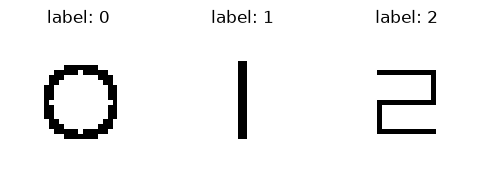

In [13]:
from lenet5 import trainingexample
from mnist import plot_images

# the three training digits, as the network gets them (before its own padding)
synthetic_labels = np.array([0, 1, 2])
synthetic_images = np.concatenate([trainingexample.create_synthetic_digit(label) for label in synthetic_labels])

print("images:", synthetic_images.shape)
plot_images(synthetic_images[:, 0], synthetic_labels)

In [14]:
trainingexample.main()

=== LeNet-5 Training Example ===

Before training:
Sample 0 (label=0): predicted=1, loss=2.3137, confidence=0.1044
Sample 1 (label=1): predicted=6, loss=2.2905, confidence=0.1016
Sample 2 (label=2): predicted=3, loss=2.3050, confidence=0.1031

=== Training ===
Epoch  10: avg_loss=2.2066, accuracy=33.3%
Epoch  20: avg_loss=2.1111, accuracy=66.7%
Epoch  30: avg_loss=1.9911, accuracy=66.7%
Epoch  40: avg_loss=1.7495, accuracy=66.7%
Epoch  50: avg_loss=1.1084, accuracy=33.3%
Epoch  60: avg_loss=0.7015, accuracy=100.0%
Epoch  70: avg_loss=0.3937, accuracy=100.0%
Epoch  80: avg_loss=0.1956, accuracy=100.0%
Epoch  90: avg_loss=0.0881, accuracy=100.0%
Epoch 100: avg_loss=0.0444, accuracy=100.0%

=== After Training ===

Sample 0 (label=0):
  Predicted: 0
  Loss: 0.0521
  Confidence: 0.9493
  All probabilities:
    Digit 0: 0.9493 (correct)
    Digit 1: 0.0001
    Digit 2: 0.0506
    Digit 3: 0.0000
    Digit 4: 0.0000
    Digit 5: 0.0000
    Digit 6: 0.0000
    Digit 7: 0.0000
    Digit 8: 0.00

**The backward pass learns.** The loss falls from about -ln(0.1) = 2.30 to close to zero and the accuracy reaches 100%, so every digit ends up with a confident, correct prediction.

## T5 - One epoch of MNIST

**With the four MNIST files in your working directory, run java MNISTTrainer 1 1 (one epoch, seed 1). It trains on the first 50,000 training images, reports accuracy on the last 10,000 training images (the validation set) every 5,000 examples, and then reports the test accuracy once. Paste the output. Validation accuracy should be well above 90% by the end of the epoch.**

I am using Python, so I converted the provided `MNISTTrainer.java`, `MNISTLoader.java`, `PerturbedMNIST.java` and `NetworkVisualizer.java` to Python in `src/lenet5/`. `python -m lenet5.mnisttrainer 1 1` (from `src/`) is the same as `java MNISTTrainer 1 1`, and so is the cell below. Differences from the Java version:

- The MNIST files are read from `data/mnist/` instead of the working directory.
- `LeNet5(seed=1)` draws its starting weights with numpy, so they are not the Java network's weights and the numbers will not match a Java run exactly.
- The shifted and noisy test images *are* the Java ones: `javarandom.py` reproduces `java.util.Random` (including `nextGaussian`), so every model is tested on exactly the same images.
- The Swing window is a matplotlib figure, shown inline at the end.

=== LeNet-5 MNIST Trainer ===

Seed 1, 1 epochs, 50000 training / 10000 validation images
Validation accuracy before training: 7.61%

 examples   mean train loss   train acc   validation acc   time
     5000            0.7963      72.28%           93.48%     6.3s
    10000            0.2026      93.84%           96.29%    12.6s
    15000            0.1624      95.22%           96.68%    18.8s
    20000            0.1207      96.24%           97.30%    25.0s
    25000            0.1066      96.72%           97.39%    31.1s
    30000            0.1169      96.56%           97.68%    37.2s
    35000            0.1017      96.82%           98.01%    43.3s
    40000            0.0900      97.44%           97.07%    49.4s
    45000            0.0947      97.48%           97.65%    55.5s
    50000            0.0934      97.36%           97.82%    61.7s

Validation accuracy first reached 97% after 20000 training examples.
TEST accuracy (reported once): 97.66%
Dead units (never positive on 1,00

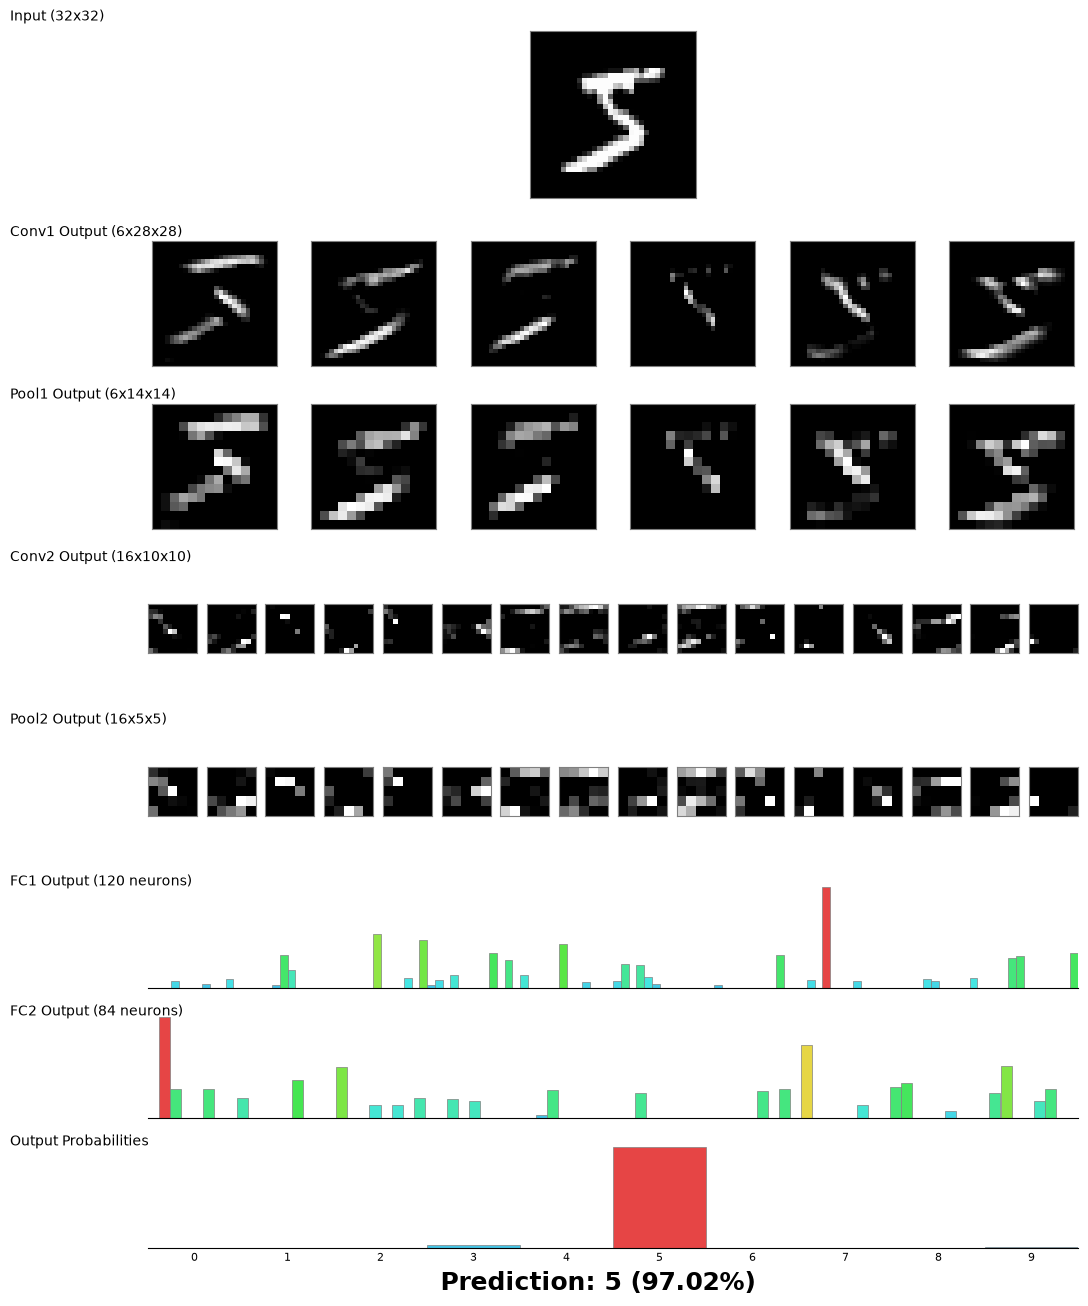

In [15]:
from lenet5 import mnisttrainer

# about 2 minutes; writes learning_curve.csv next to this notebook and shows the network on the first training image
mnist_net = mnisttrainer.main(epochs=1, seed=1)

**Output** (1 epoch, seed 1):

```
=== LeNet-5 MNIST Trainer ===

Seed 1, 1 epochs, 50000 training / 10000 validation images
Validation accuracy before training: 7.61%

 examples   mean train loss   train acc   validation acc   time
     5000            0.7963      72.28%           93.48%     8.5s
    10000            0.2026      93.84%           96.29%    17.9s
    15000            0.1624      95.22%           96.68%    25.5s
    20000            0.1207      96.24%           97.30%    31.8s
    25000            0.1066      96.72%           97.39%    39.7s
    30000            0.1169      96.56%           97.68%    47.8s
    35000            0.1017      96.82%           98.01%    56.1s
    40000            0.0900      97.44%           97.07%    64.1s
    45000            0.0947      97.48%           97.65%    72.9s
    50000            0.0934      97.36%           97.82%    81.0s

Validation accuracy first reached 97% after 20000 training examples.
TEST accuracy (reported once): 97.66%
Dead units (never positive on 1,000 validation images): C1 0/6, C3 0/16, C5 1/120, F6 0/84

Shifted test digits (d pixels horizontally and d pixels vertically):
  d = 0:  97.66%
  d = 1:  95.29%
  d = 2:  77.63%
  d = 3:  44.59%
  d = 4:  21.19%
Noisy test digits (Gaussian noise, standard deviation sigma):
  sigma = 0.1:  97.57%
  sigma = 0.2:  97.27%
  sigma = 0.3:  96.66%
  sigma = 0.4:  94.66%
  sigma = 0.5:  89.80%
```

**Well above 90%.** Validation accuracy is already 93.48% after the first 5,000 examples, passes 97% after 20,000, and ends the epoch at 97.82%. The test set, evaluated once, gives 97.66%, close to the validation accuracy, so the validation set was a fair stand-in for unseen data. The training loss falls from 0.80 to about 0.09 over the epoch.

# Part D - What do the tests tell you?

## Question 1

**Suppose T3 passes for the output layer and F6 but fails for C5, C3 and C1. Where is the bug most likely to be, and why? (Think about the order in which the backward pass computes the gradients.)**

The bug most likely must be in F6 and C5 in which is the stage where the flattening of the input has to be undone for backpropagation. Because it succeeds in the output layer and the hidden layer where it is the connection to the convolution layers, one of the most common bug that it can be is unmatched shape of the propagated delta.

## Question 2

**In T3, some parameters have an analytic and a numeric gradient that are both exactly 0. What does the check tell you about such a parameter? Give two reasons why a gradient in this network can be exactly 0 for one image.**

The check shows that the following parameter with 0 has no effect in the traning with the image loss. The gradient may be 0 because:  
1. The weight gradient is the sum of delta * input over all positions. If the input the weight multiplies is 0 at every position where the delta is non-zero, every term is 0, so the gradient is exactly 0. In this network that happens when those inputs are padding or black background.
2. ReLU is inactive so the delta for the position gets no delta (in which the z value is <= 0).

## Question 3

**T4 passes. Name two kinds of bugs that T4 would not reveal, and explain why memorizing three images is a weak test of a network with about 61,000 parameters.**

1. Data leakage bugs are shown in T4 in which the data learned by the model is used during the evaluation in which it is the same "kind" image but just transposed or scaled differently. Because the model saw the similar image in training, the loss/accuracy of the model's prediction would be optimistic. So, when it tests against new data, the model would not perform well as it have not learned useful features, making the evaluation values not representative of the true learning of the model.
2. Because LeNet5 has much of connection in the fully connected layer part, it has plenty of parameters to tell the difference between the 3 images. So, even if the model has errors in the gradients for the front convolution layers (C1, C3), T4 would not be able to show that.

Memorizing three images is a weak test because LeNet5 has many parameters, in which the images are very different and noise-free. With the many parameters that the model has, any update would be able to show downward loss and fit the points. The accuracy of 100% on the training images shows memorization rather than learning and would perform bad on any unseen images.

## Question 4

**Run TrainingExample once with initial weights in [−0.05, 0.05) (as in Lab 2) and once with [−0.1, 0.1). Report both outputs. Explain in words why smaller initial weights make a five-layer network start learning so much more slowly. (Hint: think about how large the signal is that reaches the output, and how large the error signal is that gets back to C1.)**

**Both outputs side by side** (seed 1, learning rate 0.01, 100 epochs):

| | [−0.05, 0.05) | [−0.1, 0.1) |
|---|---|---|
| loss before training | 2.302 – 2.303 | 2.291 – 2.314 |
| avg loss, epoch 10 | 2.2320 | 2.2066 |
| avg loss, epoch 50 | 1.9944 | 1.1084 |
| avg loss, epoch 100 | 1.7698 | 0.0444 |
| accuracy, epoch 100 | 66.7% | 100.0% |
| after training | every image gets ≈ 0.17 for 0, 1 and 2; all predicted 1 | each image ≥ 0.93 on its own digit |

With the smaller range the loss goes down and the network never learns to tell the three images apart. With the larger range it does by epoch 60.

**Why smaller initial weights learn so much more slowly**

The signal that reaches the output is too small as halving every weight halves each layer's output, and the five weight layers (C1, C3, C5, F6, output) multiply that together, in which the logits are (1/2)^5 = 32 times. With logits that close together, softmax gives close to the baseline prediction (probability distributed across the ouptu classes). The output barely depends on the image at all.

The error signal that gets back to C1 is essentially each weight's gradient --> (delta coming back) × (input coming forward). The delta has been multiplied by the weights of every layer above it on the backward pass, and the input by the weights of every layer below it on the way forward, which every weight gradient in C1 become (1/2)^4 = 16 times smaller. With the same learning rate, every step changes the weights 16 times less.

Thus, these two thing feed each other as tiny weights give tiny gradients, so the weights grow only slowly, so the gradients stay tiny. The only parameters whose gradient does not shrink are the output biases (their gradient is p − onehot(label) itself) and that leaves the model with no ability to tell the images apart. The [−0.1, 0.1) network starts with a signal and gradients large enough to grow out within few epoch, then fit all three images.